# 4. Modeling
We compare logistic regression, a decision tree and random forest with a simple
baseline. For each classifier, we test all variables and a smaller set chosen
with L1. We use F1 to compare the results and leave the later holdout for notebook 05.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from preparation import fill_data, scale_data, encode_data

## Load the development data
We read the clean data saved in Data Preparation and keep the same development
period. We start before scaling and encoding because these steps must be fitted
again using only the training rows of each fold.

In [2]:
train = pd.read_csv("../data/clean/train.csv", parse_dates=["purchase_date"])
train = train.sort_values(["purchase_date", "ID"]).set_index("ID")
target = "repeat_purchase_90d"

In [3]:
cut = train["purchase_date"].quantile(0.8).normalize()
gap = cut - pd.Timedelta(days=90)
dev = train.loc[train["purchase_date"] < gap].copy()

print("Development purchases:", len(dev))
print("Development ends:", dev["purchase_date"].max().date())
print("Holdout starts:", cut.date())

Development purchases: 5024
Development ends: 2023-03-18
Holdout starts: 2023-06-17


In [4]:
dev["purchase_month"] = dev["purchase_date"].dt.month.astype(str)
dev["purchase_weekday"] = dev["purchase_date"].dt.dayofweek.astype(str)

X = dev.drop(columns=["customer_id", "purchase_date", target])
y = dev[target]

## Define three temporal folds
We keep purchases from the same day together and use earlier purchases for
training. We leave 90 days before each validation period so the training labels
would already be known. Customers can appear in both periods, as we also want
to predict future purchases by customers we have seen before.

In [5]:
dates = dev["purchase_date"].sort_values().unique()
cv = TimeSeriesSplit(n_splits=3)
splits = []
rows = []

for i, split in enumerate(cv.split(dates), 1):
    idx = split[1]
    start = pd.Timestamp(dates[idx[0]])
    end = pd.Timestamp(dates[idx[-1]])
    tr = dev.index[dev["purchase_date"] < start - pd.Timedelta(days=90)]
    va = dev.index[dev["purchase_date"].between(start, end)]
    splits.append((tr, va))
    rows.append([i, len(tr), len(va), dev.loc[tr, "purchase_date"].max(), start, end])

In [6]:
res = pd.DataFrame(rows, columns=["fold", "train rows", "validation rows",
                                  "last training date", "validation starts", "validation ends"])
res

,fold,train rows,validation rows,last training date,validation starts,validation ends
0,1,994,1349,2017-07-15,2017-10-14,2019-09-17
1,2,2362,1329,2019-06-18,2019-09-20,2021-07-26
2,3,3701,1147,2021-04-27,2021-07-27,2023-03-18


## Repeat the evaluation for each model
The function below prepares each fold, trains the model and calculates F1.
We use it in all seven comparisons so the models follow the same steps.
The three preparation functions repeat the operations shown in notebook 03.

When `selection=True`, we first use logistic regression with L1 to choose the
variables, using only that fold's training data. We use `C=0.1` and keep
coefficients with an absolute value above 0.000001.

By default, a classifier predicts a repeat purchase when its probability is
above 0.5. For F1, a lower cutoff can be better: it finds more repeat purchases
at the cost of some false positives. The function therefore calculates F1 for
cutoffs from 0.20 to 0.60. Under each model we show the results at 0.5; all
cutoffs are compared at the end.

In [7]:
cutoffs = np.arange(0.20, 0.61, 0.05).round(2)


def evaluate(model, selection=False):
    rows = []
    for i, (tr, va) in enumerate(splits, 1):
        X_train, X_valid, num, cat = fill_data(X.loc[tr], X.loc[va])
        X_train, X_valid = scale_data(X_train, X_valid, num)
        X_train, X_valid = encode_data(X_train, X_valid, cat)
        y_train = y.loc[tr]
        y_valid = y.loc[va]

        if selection:
            select = LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1,
                                         max_iter=2000, random_state=42)
            select.fit(X_train, y_train)
            keep = np.abs(select.coef_[0]) > 0.000001
            cols = X_train.columns[keep]
            X_train = X_train[cols]
            X_valid = X_valid[cols]

        model.fit(X_train, y_train)
        prob = model.predict_proba(X_valid)[:, 1]
        for cutoff in cutoffs:
            pred = (prob > cutoff).astype(int)
            f1 = f1_score(y_valid, pred)
            rows.append([i, X_train.shape[1], cutoff, f1])

    res = pd.DataFrame(rows, columns=["fold", "n_features", "cutoff", "F1"])
    return res

## Majority-class baseline
The baseline always predicts the most common class in its training fold.
We use its F1 values as a reference for the other models.

In [8]:
scores = []
model = DummyClassifier(strategy="most_frequent")
res = evaluate(model)
res["model"] = "Baseline"
res["features"] = "All"
scores.append(res)
res.loc[res["cutoff"] == 0.5].round(4)

,fold,n_features,cutoff,F1,model,features
6,1,140,0.5,0.7128,Baseline,All
15,2,189,0.5,0.7233,Baseline,All
24,3,234,0.5,0.6770,Baseline,All


## Logistic regression
We start with `C=1` and all variables. We then repeat the evaluation with the
variables selected by L1. We keep the model settings fixed across the folds.

In [9]:
model = LogisticRegression(C=1, solver="liblinear", max_iter=2000, random_state=42)
res = evaluate(model)
res["model"] = "Logistic regression"
res["features"] = "All"
scores.append(res)
res.loc[res["cutoff"] == 0.5].round(4)

,fold,n_features,cutoff,F1,model,features
6,1,140,0.5,0.6758,Logistic regression,All
15,2,189,0.5,0.6620,Logistic regression,All
24,3,234,0.5,0.6955,Logistic regression,All


With L1 selection:

In [10]:
res = evaluate(model, selection=True)
res["model"] = "Logistic regression"
res["features"] = "L1"
scores.append(res)
res.loc[res["cutoff"] == 0.5].round(4)

,fold,n_features,cutoff,F1,model,features
6,1,19,0.5,0.7462,Logistic regression,L1
15,2,31,0.5,0.7111,Logistic regression,L1
24,3,41,0.5,0.7310,Logistic regression,L1


## Decision tree
We limit the tree to depth 5 and require at least 20 purchases per leaf.
This limits rules based on very small groups of purchases.

In [11]:
model = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42)
res = evaluate(model)
res["model"] = "Decision tree"
res["features"] = "All"
scores.append(res)
res.loc[res["cutoff"] == 0.5].round(4)

,fold,n_features,cutoff,F1,model,features
6,1,140,0.5,0.7368,Decision tree,All
15,2,189,0.5,0.7110,Decision tree,All
24,3,234,0.5,0.7193,Decision tree,All


With L1 selection:

In [12]:
res = evaluate(model, selection=True)
res["model"] = "Decision tree"
res["features"] = "L1"
scores.append(res)
res.loc[res["cutoff"] == 0.5].round(4)

,fold,n_features,cutoff,F1,model,features
6,1,19,0.5,0.7320,Decision tree,L1
15,2,31,0.5,0.7220,Decision tree,L1
24,3,41,0.5,0.7156,Decision tree,L1


## Random forest
We use 200 trees and a minimum of 5 purchases per leaf. We keep the random
seed fixed so we can reproduce the comparison.

In [13]:
model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                random_state=42, n_jobs=2)
res = evaluate(model)
res["model"] = "Random forest"
res["features"] = "All"
scores.append(res)
res.loc[res["cutoff"] == 0.5].round(4)

,fold,n_features,cutoff,F1,model,features
6,1,140,0.5,0.7492,Random forest,All
15,2,189,0.5,0.7340,Random forest,All
24,3,234,0.5,0.7296,Random forest,All


With L1 selection:

In [14]:
res = evaluate(model, selection=True)
res["model"] = "Random forest"
res["features"] = "L1"
scores.append(res)
res.loc[res["cutoff"] == 0.5].round(4)

,fold,n_features,cutoff,F1,model,features
6,1,19,0.5,0.7505,Random forest,L1
15,2,31,0.5,0.7264,Random forest,L1
24,3,41,0.5,0.7395,Random forest,L1


## Compare the results
We join the results and compare the average F1 over the three folds, first at
the default cutoff of 0.5 and then at each model's best cutoff. The standard
deviation shows how much the scores vary between folds; it is not a confidence
interval.

In [15]:
scores = pd.concat(scores, ignore_index=True)
summary = scores.groupby(["model", "features", "cutoff"])["F1"].agg(["mean", "std"])
summary = summary.reset_index()
summary.loc[summary["cutoff"] == 0.5].sort_values("mean", ascending=False).round(4)

,model,features,cutoff,mean,std
60,Random forest,L1,0.5,0.7388,0.0120
51,Random forest,All,0.5,0.7376,0.0103
42,Logistic regression,L1,0.5,0.7294,0.0176
24,Decision tree,L1,0.5,0.7232,0.0082
15,Decision tree,All,0.5,0.7223,0.0132
6,Baseline,All,0.5,0.7044,0.0243
33,Logistic regression,All,0.5,0.6778,0.0168


In [16]:
best = summary.loc[summary.groupby(["model", "features"])["mean"].idxmax()]
best = best.sort_values("mean", ascending=False)
best.round(4)

,model,features,cutoff,mean,std
49,Random forest,All,0.4,0.7457,0.0125
58,Random forest,L1,0.4,0.7451,0.0132
40,Logistic regression,L1,0.4,0.7431,0.0076
13,Decision tree,All,0.4,0.7283,0.0073
22,Decision tree,L1,0.4,0.7271,0.0076
29,Logistic regression,All,0.3,0.7186,0.0210
0,Baseline,All,0.2,0.7044,0.0243


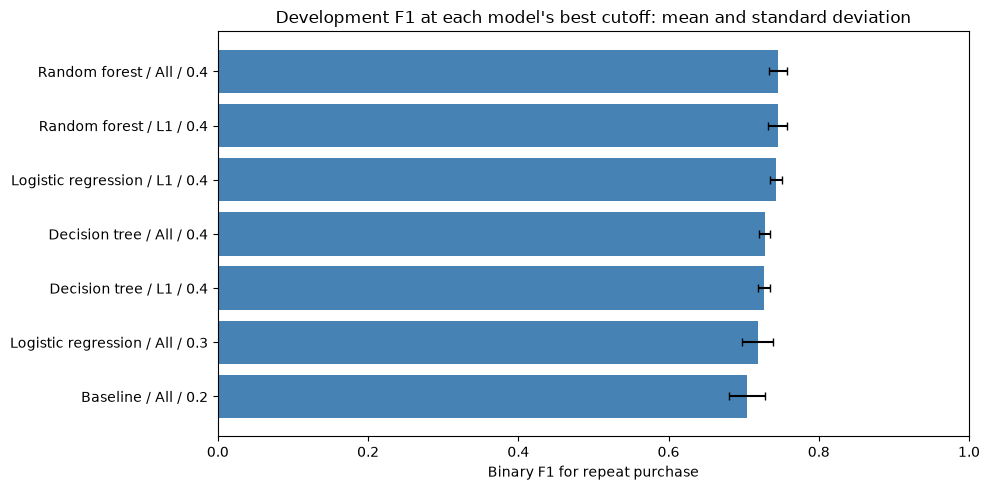

In [17]:
res = best.sort_values("mean")
labels = res["model"] + " / " + res["features"] + " / " + res["cutoff"].astype(str)
plt.figure(figsize=(10, 5))
plt.barh(labels, res["mean"], xerr=res["std"], color="steelblue", capsize=3)
plt.title("Development F1 at each model's best cutoff: mean and standard deviation")
plt.xlabel("Binary F1 for repeat purchase")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

At the default 0.5 cutoff, random forest with L1 has the highest average F1:
**0.7388**, compared with **0.7044** for the baseline.

Every classifier improves with a lower cutoff, and 0.40 is the best cutoff for
all of them except logistic regression with all variables. At 0.40, the forest
with all variables scores **0.7457** and the forest with L1 **0.7451**. The
difference, 0.0006, is far smaller than the variation between folds (standard
deviation about 0.013), so we treat the two as tied and choose the simpler one:
**random forest + L1 with cutoff 0.40**, which uses 19 to 41 inputs per fold
instead of 140 to 234. Logistic regression with L1 is close behind (0.7431).
The baseline predicts the same class at every cutoff. We have not tuned
hyperparameters.

In [18]:
chosen = (best["model"] == "Random forest") & (best["features"] == "L1")
cutoff = best.loc[chosen, "cutoff"].item()
print("Cutoff for random forest + L1:", cutoff)

Cutoff for random forest + L1: 0.4


## Select variables using all development data
We now read the prepared matrix from notebook 03, with 5,024 purchases.
We fit L1 again on this full development set before training the chosen forest.

In [19]:
train = pd.read_csv("../data/prepared/train.csv", index_col="ID")
X_train = train.drop(columns=target)
y_train = train[target]

In [20]:
select = LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1,
                             max_iter=2000, random_state=42)
select.fit(X_train, y_train)
keep = np.abs(select.coef_[0]) > 0.000001
cols = X_train.columns[keep].tolist()
print("Selected inputs:", len(cols), "of", X_train.shape[1])

Selected inputs: 52 of 273


In [21]:
res = pd.Series(select.coef_[0], index=X_train.columns, name="coefficient")
res = res.loc[cols]
res = res.loc[res.abs().sort_values(ascending=False).index]
res.head(15).round(3)

purchase_count_365d                                            1.197
island_Missing                                                 0.571
purchase_count_90d                                             0.521
country_or_region_Country CT10: Land of The Final Version      0.427
purchase_month_9                                               0.379
purchase_month_12                                             -0.255
purchase_month_11                                             -0.253
purchase_weekday_0                                             0.250
purchase_month_3                                              -0.239
purchase_month_4                                              -0.228
municipality_Municipality MU9: Council of Last Minute Edits    0.220
prior_max_purchase_value                                       0.219
postal_area_infrequent_sklearn                                -0.213
Total Desc_ Linha                                              0.202
spend_90d                         

L1 kept **52 of the 273 variables**. These coefficients come from the logistic
regression used for selection; they are not random forest importance scores.
`random_noise`, `Total Portes` and the purchase year are not used, as explained
in Data Preparation.

## Train the chosen forest
We use the same forest settings as above. In the next notebook, we evaluate
this model on the later holdout without using it to choose a new solution.

In [22]:
model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                random_state=42, n_jobs=2)
model.fit(X_train[cols], y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

## Save the model and results
We save the forest, the selected variables, the comparison tables and the
chosen cutoff.
Evaluation reads these files. Deployment trains the same method again
using all 6,469 training purchases with a date.

In [23]:
os.makedirs("../results", exist_ok=True)
scores.to_csv("../results/cv_results.csv", index=False)
summary.to_csv("../results/cv_summary.csv", index=False)
best.to_csv("../results/cv_best_cutoffs.csv", index=False)
pd.DataFrame({"cutoff": [cutoff]}).to_csv("../results/chosen_cutoff.csv", index=False)
pd.Series(cols, name="feature").to_csv("../results/selected_features.csv", index=False)
joblib.dump(model, "../results/development_model.joblib")

['../results/development_model.joblib']

Next: [Evaluation](05_Evaluation.ipynb).